# Develop a decision tree classifier to detect malicious data injections within databases.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("Modified_SQL_Dataset.csv")
df = df.dropna()
print(df.shape)
print(df["Label"].value_counts())
print(df.head())

(30919, 2)
Label
0    19537
1    11382
Name: count, dtype: int64
                                               Query  Label
0                  " or pg_sleep  (  __TIME__  )  --      1
1  create user name identified by pass123 tempora...      1
2   AND 1  =  utl_inaddr.get_host_address   (    ...      1
3   select * from users where id  =  '1' or @ @1 ...      1
4   select * from users where id  =  1 or 1#"  ( ...      1


In [3]:
SQL_KEYWORDS = ["select", "union", "insert", "update", "delete", "drop", "from",
                "where", "and", "or", "exec", "sleep", "benchmark", "information_schema"]

def get_features(query):
    q = str(query).lower()
    return pd.Series({
        "length": len(q),
        "single_quotes": q.count("'"),
        "double_quotes": q.count('"'),
        "comments": q.count("--") + q.count("#") + q.count("/*"),
        "semicolons": q.count(";"),
        "parentheses": q.count("(") + q.count(")"),
        "equals_signs": q.count("="),
        "special_chars": len(re.findall(r"[^a-z0-9\s]", q)),
        "sql_keywords": sum(len(re.findall(rf"\b{k}\b", q)) for k in SQL_KEYWORDS),
        "has_union_select": int("union" in q and "select" in q),
        "always_true": int(bool(re.search(r"(\d+)\s*=\s*\1|'\w*'\s*=\s*'\w*'", q))),  # e.g. 1=1, 'a'='a'
        "has_or": int(bool(re.search(r"\bor\b", q))),
        "has_hex": int(bool(re.search(r"0x[0-9a-f]+", q))),
        "time_based": int("sleep" in q or "benchmark" in q or "waitfor" in q),
    })

X = df["Query"].apply(get_features)
y = df["Label"]
print(X.head())

   length  single_quotes  double_quotes  comments  semicolons  parentheses  \
0      33              0              1         1           0            2   
1      90              0              0         0           1            0   
2     218              3              0         0           0           10   
3      90              3              0         1           0            2   
4      85              0              1         2           0            3   

   equals_signs  special_chars  sql_keywords  has_union_select  always_true  \
0             0             10             1                 0            0   
1             0              1             0                 0            0   
2             3             25             7                 0            0   
3             2             13             6                 1            1   
4             1             10             6                 1            0   

   has_or  has_hex  time_based  
0       1        0     

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [5]:
model = DecisionTreeClassifier(max_depth=8, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)


Accuracy: 0.9929
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      3908
   Malicious       1.00      0.98      0.99      2276

    accuracy                           0.99      6184
   macro avg       0.99      0.99      0.99      6184
weighted avg       0.99      0.99      0.99      6184



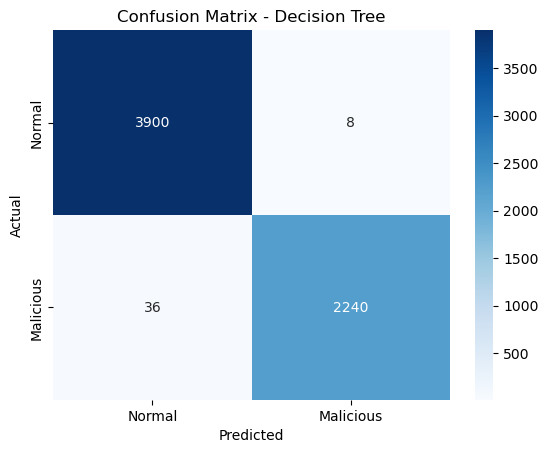

In [6]:
print("\nAccuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["Normal", "Malicious"]))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Malicious"], yticklabels=["Normal", "Malicious"])
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

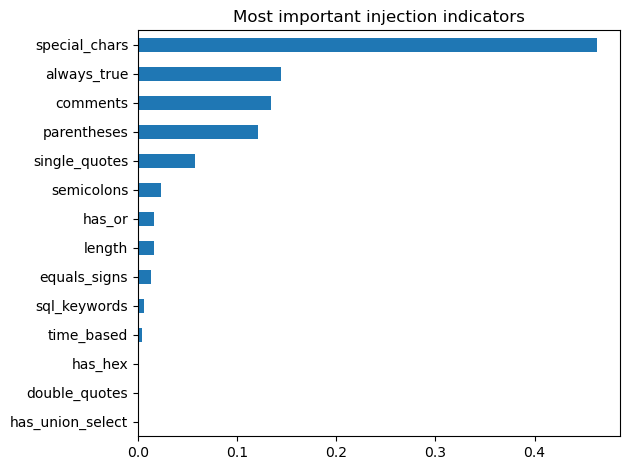

In [7]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", title="Most important injection indicators")
plt.tight_layout()
plt.show()

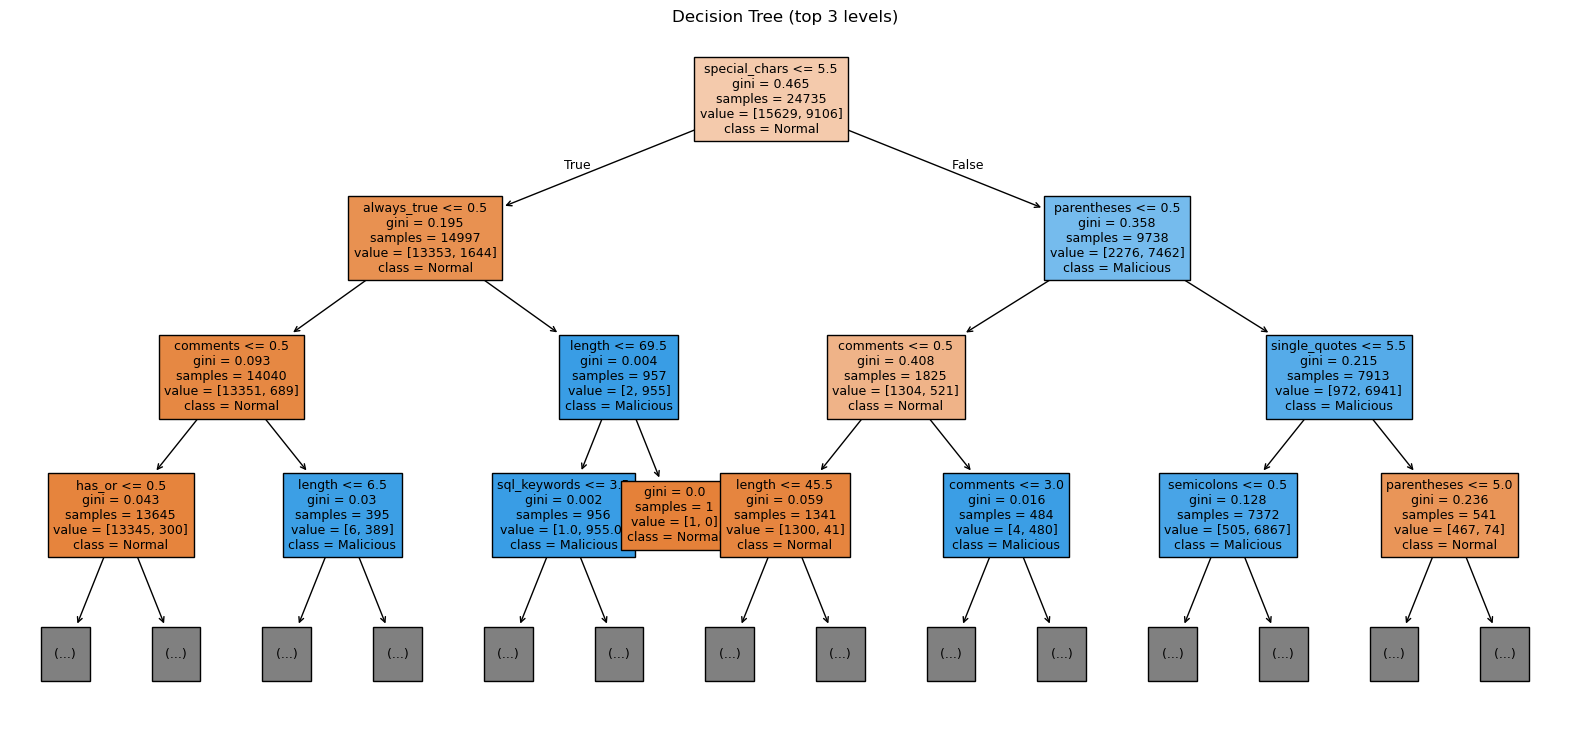

In [8]:
plt.figure(figsize=(20, 9))
plot_tree(model, feature_names=X.columns, class_names=["Normal", "Malicious"],
          filled=True, max_depth=3, fontsize=9)
plt.title("Decision Tree (top 3 levels)")
plt.show()

In [9]:
tests = [
    "SELECT name FROM users WHERE id = 5",
    "admin' OR 1=1 --",
    "john.smith@example.com",
    "1; DROP TABLE users",
    "' UNION SELECT username, password FROM users --",
]
for t in tests:
    result = model.predict(get_features(t).to_frame().T)[0]
    print(f"{'MALICIOUS' if result == 1 else 'Normal':10s} <- {t}")

Normal     <- SELECT name FROM users WHERE id = 5
MALICIOUS  <- admin' OR 1=1 --
Normal     <- john.smith@example.com
Normal     <- 1; DROP TABLE users
MALICIOUS  <- ' UNION SELECT username, password FROM users --
